<a href="https://colab.research.google.com/github/Jegovila/cursoVR/blob/main/Practica18%20LBP/python/LBP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!wget -nc "https://raw.githubusercontent.com/Jegovila/cursoVR/refs/heads/main/Practica18%20LBP/python/madera.webp"
!wget -nc "https://raw.githubusercontent.com/Jegovila/cursoVR/refs/heads/main/Practica18%20LBP/python/texturas.webp"
!wget -nc "https://raw.githubusercontent.com/Jegovila/cursoVR/refs/heads/main/Practica18%20LBP/python/ventanas.webp"

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern
import ipywidgets as widgets
from IPython.display import display

# LBP

Cargar imagen

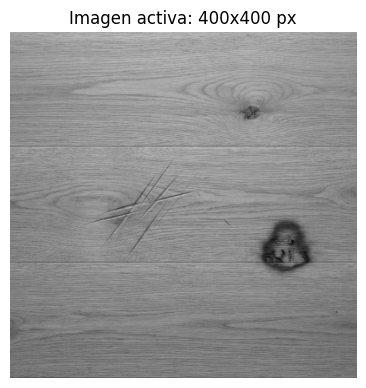

In [ ]:
img_bgr = cv2.imread("madera.webp")
if img_bgr is None:
  print(f"AVISO: No se encontró la imagen. Usando imagen de ejemplo...")
  from skimage import data
  img_demo = cv2.resize(data.brick(), (400, 260))
else:
  # Redimensionar manteniendo proporción para que los sliders de las siguientes celdas funcionen fluido
  ancho_objetivo = 400
  escala = ancho_objetivo / img_bgr.shape[1]
  alto_objetivo = int(img_bgr.shape[0] * escala)
  img_bgr = cv2.resize(img_bgr, (ancho_objetivo, alto_objetivo), interpolation=cv2.INTER_AREA)
  img_demo = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Mostrar imagen base
plt.figure(figsize=(7, 4.5))
plt.imshow(img_demo, cmap='gray', vmin=0, vmax=255)
plt.title(f"Imagen activa: {img_demo.shape[1]}x{img_demo.shape[0]} px")
plt.axis('off')
plt.show()

In [ ]:
pesos = np.array([
    [1,   2,  4],
    [128, 0,  8],
    [64, 32, 16]
], dtype=np.uint8)

def inspeccionar_lbp_manual(cx, cy, brillo_extra):
    # Simular cambio de iluminación global para demostrar invarianza
    img_luz = np.clip(img_demo.astype(np.int16) + brillo_extra, 0, 255).astype(np.uint8)

    parche = img_luz[cy-1:cy+2, cx-1:cx+2]
    centro = parche[1, 1]
    binario = (parche >= centro).astype(np.uint8)
    binario[1, 1] = 0 #apagamos el pixel central para que no sume
    valor_lbp = int(np.sum(binario * pesos))

    fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))

    # 1. Ubicación en la imagen
    axes[0].imshow(img_luz, cmap='gray', vmin=0, vmax=255)
    axes[0].plot(cx, cy, 'ro', markersize=8)
    axes[0].set_title(f"Imagen (Brillo: {brillo_extra:+d})")
    axes[0].axis('off')

    # 2. Vecindad 3x3 real
    axes[1].imshow(parche, cmap='gray', vmin=0, vmax=255)
    for i in range(3):
        for j in range(3):
            color = 'red' if (i == 1 and j == 1) else 'cyan'
            axes[1].text(j, i, str(parche[i, j]), ha='center', va='center', color=color, fontsize=13, fontweight='bold')
    axes[1].set_title(f"Parche 3x3 (Centro={centro})")
    axes[1].set_xticks([]); axes[1].set_yticks([])

    # 3. Umbralización (0 o 1)
    axes[2].imshow(binario, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            txt = "C" if (i == 1 and j == 1) else str(binario[i, j])
            axes[2].text(j, i, txt, ha='center', va='center', color='black', fontsize=14, fontweight='bold')
    axes[2].set_title("Comparación (>= Centro)")
    axes[2].set_xticks([]); axes[2].set_yticks([])

    # 4. Multiplicación por pesos
    contribucion = binario * pesos
    axes[3].imshow(contribucion, cmap='Oranges', vmin=0, vmax=128)
    for i in range(3):
        for j in range(3):
            txt = "-" if (i == 1 and j == 1) else f"{binario[i,j]}x{pesos[i,j]}"
            axes[3].text(j, i, txt, ha='center', va='center', color='black', fontsize=11, fontweight='bold')
    axes[3].set_title(f"Código LBP Final = {valor_lbp}")
    axes[3].set_xticks([]); axes[3].set_yticks([])

    plt.tight_layout()
    plt.show()

widgets.interact(
    inspeccionar_lbp_manual,
    cx=widgets.IntSlider(min=2, max=img_demo.shape[1]-3, step=1, value=img_demo.shape[1]//2, description='Pos X:'),
    cy=widgets.IntSlider(min=2, max=img_demo.shape[0]-3, step=1, value=img_demo.shape[0]//2, description='Pos Y:'),
    brillo_extra=widgets.IntSlider(min=-80, max=80, step=10, value=0, description='Brillo:')
);

interactive(children=(IntSlider(value=200, description='Pos X:', max=397, min=2), IntSlider(value=200, descrip…

Funcionamiento en tiempo real de los hiperparámetros clave de LBP. El siguiente bloque demuestra tres conecptor teóricos clave:


1.   La dimensión (tamaño del histograma con método y Slider P)
2.   Invarianza a la rotación (método ror)
3.   Escala de la textura (Slider R)



In [ ]:
def explorar_skimage_lbp(metodo, P, R):

    img_bgr_madera = cv2.imread("madera.webp")
    if img_bgr_madera is None:
      print(f"AVISO: No se encontró la imagen. Usando imagen de ejemplo...")
      from skimage import data
      img_demo_3 = cv2.resize(data.brick(), (400, 260))
    else:
      # Redimensionar manteniendo proporción para que los sliders de las siguientes celdas funcionen fluido
      ancho_objetivo = 400
      escala = ancho_objetivo / img_bgr_madera.shape[1]
      alto_objetivo = int(img_bgr_madera.shape[0] * escala)
      img_bgr = cv2.resize(img_bgr_madera, (ancho_objetivo, alto_objetivo), interpolation=cv2.INTER_AREA)
      img_demo_3 = cv2.cvtColor(img_bgr_madera, cv2.COLOR_BGR2GRAY)

    lbp = local_binary_pattern(img_demo_3, P=P, R=R, method=metodo)
    n_bins = P + 2 if metodo == 'uniform' else 2**P

    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(n_bins + 1) - 0.5, density=True)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    axes[0].imshow(cv2.cvtColor(img_bgr_madera, cv2.COLOR_BGR2RGB), cmap='viridis')
    axes[0].set_title(f"Mapa LBP (method='{metodo}', P={P}, R={R})")
    axes[0].axis('off')

    axes[1].imshow(lbp, cmap='viridis')
    axes[1].set_title(f"Mapa LBP (method='{metodo}', P={P}, R={R})")
    axes[1].axis('off')

    axes[2].bar(range(n_bins), hist, color='teal', edgecolor='black' if n_bins <= 20 else None)
    axes[2].set_title(f"Histograma Normalizado ({n_bins} bins)")
    axes[2].set_xlabel("Bin (Patrón LBP)")
    axes[2].set_ylabel("Proporción de área")
    axes[2].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

widgets.interact(
    explorar_skimage_lbp,
    metodo=widgets.Dropdown(options=['uniform', 'default', 'ror'], value='uniform', description='Método:'),
    P=widgets.IntSlider(min=4, max=16, step=4, value=8, description='Puntos (P):'),
    R=widgets.IntSlider(min=1, max=4, step=1, value=1, description='Radio (R):')
);

interactive(children=(Dropdown(description='Método:', options=('uniform', 'default', 'ror'), value='uniform'),…

Esta celda lleva los conceptos teóricos de LBP a una aplicación industrial real: inspección visual automatizada (control de calidad en telas, madera, metal o superficies) mediante una ventana deslizante. Podemos buscar **texturas similares o defectos**.

In [ ]:
# Precalcular mapa LBP una sola vez
lbp_full = local_binary_pattern(img_demo, P=8, R=1, method='uniform')

def calc_hist(patch):
    h, _ = np.histogram(patch.ravel(), bins=np.arange(11) - 0.5)
    h = h.astype(np.float32)
    return h / h.sum() if h.sum() > 0 else h

def detectar_anomalias_y_matches(ref_x, ref_y, tam_ventana, umbral_similitud, modo):
    ref_patch = lbp_full[ref_y:ref_y+tam_ventana, ref_x:ref_x+tam_ventana]
    ref_hist = calc_hist(ref_patch)

    vis = cv2.cvtColor(img_demo, cv2.COLOR_GRAY2RGB)
    H, W = lbp_full.shape
    paso = max(6, tam_ventana // 3)

    conteo = 0
    for y in range(0, H - tam_ventana + 1, paso):
        for x in range(0, W - tam_ventana + 1, paso):
            win = lbp_full[y:y+tam_ventana, x:x+tam_ventana]
            win_hist = calc_hist(win)
            sim = 1.0 - cv2.compareHist(ref_hist, win_hist, cv2.HISTCMP_BHATTACHARYYA)

            if modo == 'Buscar textura similar (Verde)' and sim >= umbral_similitud:
                cv2.rectangle(vis, (x, y), (x+tam_ventana, y+tam_ventana), (0, 220, 0), 1)
                conteo += 1
            elif modo == 'Detectar defectos / anomalías (Rojo)' and sim < umbral_similitud:
                cv2.rectangle(vis, (x, y), (x+tam_ventana, y+tam_ventana), (255, 40, 40), 1)
                conteo += 1

    # Dibujar cuadro de referencia sana en azul
    cv2.rectangle(vis, (ref_x, ref_y), (ref_x+tam_ventana, ref_y+tam_ventana), (0, 120, 255), 2)

    plt.figure(figsize=(9, 5))
    plt.imshow(vis)
    plt.title(f"Ref Azul=({ref_x},{ref_y}) | Umbral={umbral_similitud*100:.0f}% | Ventanas marcadas={conteo}")
    plt.axis('off')
    plt.show()

widgets.interact(
    detectar_anomalias_y_matches,
    ref_x=widgets.IntSlider(min=0, max=img_demo.shape[1]-60, step=5, value=20, description='Ref X:'),
    ref_y=widgets.IntSlider(min=0, max=img_demo.shape[0]-60, step=5, value=20, description='Ref Y:'),
    tam_ventana=widgets.IntSlider(min=20, max=60, step=5, value=30, description='Tamaño:'),
    umbral_similitud=widgets.FloatSlider(min=0.50, max=0.98, step=0.02, value=0.85, description='Similitud:'),
    modo=widgets.Dropdown(
        options=['Buscar textura similar (Verde)', 'Detectar defectos / anomalías (Rojo)'],
        value='Detectar defectos / anomalías (Rojo)',
        description='Modo:'
    )
);

interactive(children=(IntSlider(value=20, description='Ref X:', max=340, step=5), IntSlider(value=20, descript…